# 06_08 Risk, Relative Risk and Odds Ratio (a short lesson)

**Learning objectives**
- Summarise a $2\times2$ table with the **risk difference**, **relative risk (RR)** and **odds ratio (OR)**, and give confidence intervals for them.
- Use **Fisher's exact test** for small tables, and know when the odds ratio is a good stand-in for the relative risk.
- Read these numbers correctly in a medical study, a case-control study and an A/B test.

**Prerequisites:** [06_02 Confidence intervals](06_02_confidence_intervals.ipynb), [06_04 Common tests](06_04_common_tests.ipynb) (chi-square for tables), [06_07 A/B testing](06_07_ab_testing.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

import math, pathlib
df = pd.read_csv('../data/cookie_cats.csv') if pathlib.Path('../data/cookie_cats.csv').exists() else pd.read_csv('module_06_inference/data/cookie_cats.csv')

## 2. Prerequisite recap
A $2\times2$ table counts how many of $n_1$ exposed and $n_0$ unexposed units have the outcome. Chi-square (06_04) tests *whether* the groups differ; this lesson measures *how much* they differ, in three languages.

## 3. Intuition and story
"Taking the drug halves your odds of a heart attack" and "cuts your risk by 30 %" sound alike but are different numbers, and mixing them up is one of the most common errors in reading studies and A/B tests. **Risk** is a probability ($p$); **odds** are $p/(1-p)$. For a rare outcome they are almost equal; for a common outcome the odds ratio looks much more extreme than the relative risk.

## 4. Formal definitions
With $a$ events out of $n_1$ in the exposed group and $c$ events out of $n_0$ in the unexposed group ($p_1=a/n_1$, $p_0=c/n_0$):

| Measure | Formula | Meaning |
|---|---|---|
| **Risk difference** | $p_1-p_0$ | extra events per exposed unit |
| **Relative risk** | $\mathrm{RR}=p_1/p_0$ | how many times as likely |
| **Odds ratio** | $\mathrm{OR}=\dfrac{p_1/(1-p_1)}{p_0/(1-p_0)}=\dfrac{ad}{bc}$ | ratio of odds, $b=n_1-a$, $d=n_0-c$ |
| **Number needed to treat** | $1/|p_1-p_0|$ | units that must be exposed for one extra event |

Large-sample intervals use the log scale: $\log\mathrm{RR}\pm z\sqrt{\frac1a-\frac1{n_1}+\frac1c-\frac1{n_0}}$ and $\log\mathrm{OR}\pm z\sqrt{\frac1a+\frac1b+\frac1c+\frac1d}$ (Woolf), then exponentiate.

## 5. Derivations
**Standard error of $\log\mathrm{RR}$ (delta method, 05_06).** $\hat p_1,\hat p_0$ are independent with $\mathrm{Var}(\hat p)=p(1-p)/n$. For $g(p)=\log p$, $g'(p)=1/p$, so $\mathrm{Var}(\log\hat p)\approx\frac{1-p}{np}=\frac1{np}-\frac1n$. Adding the two groups gives $\frac1a-\frac1{n_1}+\frac1c-\frac1{n_0}$ with $a=n_1p_1$, $c=n_0p_0$. **In plain words.** The relative risk is a ratio, so we work with its logarithm, where the error is a plain sum.

**OR is approximately RR for rare outcomes.** $\mathrm{OR}=\mathrm{RR}\times\dfrac{1-p_0}{1-p_1}$, and the last factor tends to 1 when both risks are small. **In plain words.** For rare events risk and odds are the same thing.

**Symmetry of the OR.** $ad/bc$ is unchanged when rows and columns are swapped, which is why case-control studies (sampling by outcome) can still estimate the OR, but not the RR.

## 6. Properties and relationships
- RR depends on which outcome is called the "event" ($\mathrm{RR}$ for retention differs from $\mathrm{RR}$ for churn); the OR just inverts. Always state the baseline risk next to a relative number.
- **Fisher's exact test** conditions on the margins: the count $a$ is Hypergeometric (01_04) under $H_0$, so the p-value is exact for small tables.
- **Link to ML and AI:** the coefficient of a logistic regression is a log odds ratio; "feature X doubles the odds" is read from $e^\beta$. Reporting absolute risk changes next to ORs avoids exaggeration of model effects.

## 7. 2D visuals

### 7.1 OR against RR
For a fixed relative risk the odds ratio drifts away from it as the baseline risk $p_0$ grows.

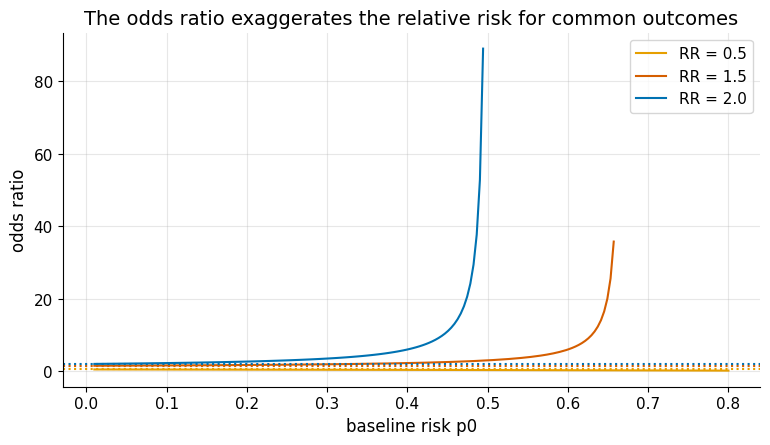

In [2]:
p0g = np.linspace(0.01, 0.8, 200); fig, ax = plt.subplots(figsize=(9, 4.6))
for rr_, colr in [(0.5, SIM), (1.5, HIGHLIGHT), (2.0, MAIN)]:
    p1 = np.minimum(rr_ * p0g, 0.999); ax.plot(p0g[p1 < 0.99], ((p1 / (1 - p1)) / (p0g / (1 - p0g)))[p1 < 0.99], color=colr, label=f"RR = {rr_}"); ax.axhline(rr_, color=colr, linestyle=":")
ax.set_xlabel("baseline risk p0"); ax.set_ylabel("odds ratio"); ax.set_title("The odds ratio exaggerates the relative risk for common outcomes"); ax.legend()
plt.show()
rr_, p0_ = 2.0, 0.3; p1_ = rr_ * p0_; assert abs((p1_ / (1 - p1_)) / (p0_ / (1 - p0_)) - 3.5) < 1e-3

### 7.2 Confidence interval widths
The interval of the RR for a fixed $p_1=0.2,\ p_0=0.25$ shrinks like $1/\sqrt n$.

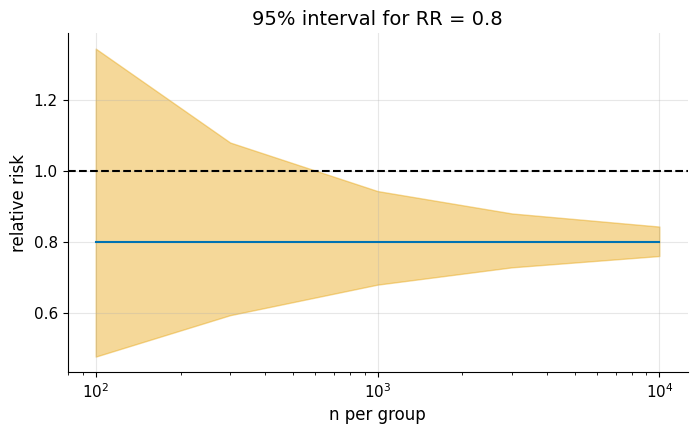

In [3]:
nsz = np.array([100, 300, 1000, 3000, 10000]); lo, hi = [], []
for n_ in nsz:
    a_, c_ = 0.2 * n_, 0.25 * n_; s_ = np.sqrt(1 / a_ - 1 / n_ + 1 / c_ - 1 / n_); lo.append(0.8 * np.exp(-1.96 * s_)); hi.append(0.8 * np.exp(1.96 * s_))
fig, ax = plt.subplots(figsize=(8, 4.4)); ax.fill_between(nsz, lo, hi, color=SIM, alpha=0.4); ax.plot(nsz, np.full(5, 0.8), color=MAIN); ax.axhline(1, color="black", linestyle="--"); ax.set_xscale("log"); ax.set_xlabel("n per group"); ax.set_ylabel("relative risk"); ax.set_title("95% interval for RR = 0.8")
plt.show()

## 8. 3D visuals

### 8.1 Static: the odds ratio over (baseline risk, relative risk)
For $\mathrm{RR}>1$ the surface rises well above the RR plane; the bigger the baseline risk the bigger the gap.

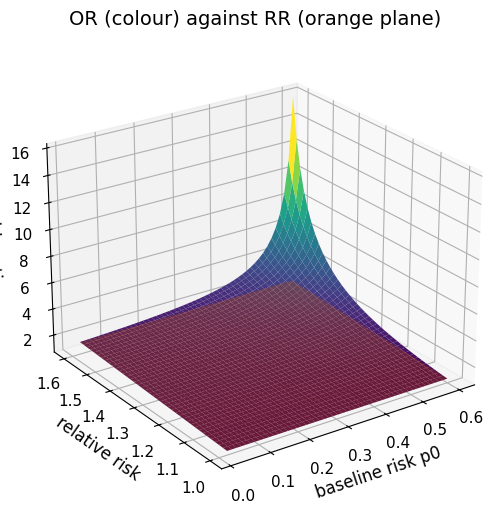

In [4]:
pg = np.linspace(0.02, 0.6, 50); rg = np.linspace(1.0, 1.6, 40); Pg, Rg = np.meshgrid(pg, rg); P1 = np.minimum(Pg * Rg, 0.99); ORs = (P1 / (1 - P1)) / (Pg / (1 - Pg))
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Pg, Rg, ORs, cmap="viridis", edgecolor="none"); ax.plot_surface(Pg, Rg, Rg, color=HIGHLIGHT, alpha=0.3, edgecolor="none")
ax.set_xlabel("baseline risk p0"); ax.set_ylabel("relative risk"); ax.set_zlabel("odds ratio"); ax.set_title("OR (colour) against RR (orange plane)"); ax.view_init(elev=24, azim=-125)
plt.show()

### 8.2 Interactive Plotly version of 8.1

In [5]:
fig = go.Figure(go.Surface(x=pg, y=rg, z=ORs, colorscale="Viridis")); fig.update_layout(title="Odds ratio", width=760, height=560, scene=dict(xaxis_title="p0", yaxis_title="RR", zaxis_title="OR")); fig.show()

## 9. Simulation vs theory
Simulate 20,000 studies with true $p_1=0.18$, $p_0=0.20$ ($n=3{,}000$ per group): the log-RR interval should cover the true RR about 95 % of the time.

In [6]:
g = np.random.default_rng(3); R = 20000; n_ = 3000; a_ = g.binomial(n_, 0.18, R); c_ = g.binomial(n_, 0.20, R); lrr = np.log((a_ / n_) / (c_ / n_)); se_ = np.sqrt(1 / a_ - 1 / n_ + 1 / c_ - 1 / n_)
cover = np.mean((lrr - 1.96 * se_ <= np.log(0.9)) & (np.log(0.9) <= lrr + 1.96 * se_)); print(f"coverage of the RR interval: {cover:.4f}; mean log RR {lrr.mean():.4f} (true {np.log(0.9):.4f})")
assert abs(cover - 0.95) < 0.006 and abs(lrr.mean() - np.log(0.9)) < 0.003

coverage of the RR interval: 0.9490; mean log RR -0.1057 (true -0.1054)


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [7]:
tab = [[8, 2], [3, 9]]
print("stats.fisher_exact(table) ->", stats.fisher_exact(tab))
print("stats.contingency.relative_risk(a, n1, c, n0).confidence_interval() ->", stats.contingency.relative_risk(8, 10, 3, 12).confidence_interval())
print("stats.contingency.odds_ratio(table).confidence_interval() ->", stats.contingency.odds_ratio(tab).confidence_interval())
print("stats.chi2_contingency(table, correction=False)[1] ->", round(stats.chi2_contingency(tab, correction=False)[1], 4), "| Hypergeometric exact tail: stats.hypergeom")

stats.fisher_exact(table) -> SignificanceResult(statistic=np.float64(12.0), pvalue=np.float64(0.029973122852379817))
stats.contingency.relative_risk(a, n1, c, n0).confidence_interval() -> ConfidenceInterval(low=np.float64(1.1449225871738908), high=np.float64(8.94383612893537))
stats.contingency.odds_ratio(table).confidence_interval() -> ConfidenceInterval(low=1.189667992888677, high=157.37815583763205)
stats.chi2_contingency(table, correction=False)[1] -> 0.0102 | Hypergeometric exact tail: stats.hypergeom


## 11. Real-world worked examples

---
### Example 1 (main): Cookie Cats 7-day retention as a $2\times2$ table
**Scenario.** 8,279 of 45,489 `gate_40` players and 8,502 of 44,700 `gate_30` players returned after 7 days (real data, 06_07).

**Questions**
1. Compute the risk difference, relative risk and odds ratio with 95 % intervals.
2. Test with Fisher's exact test; compare with the chi-square p-value.
3. How many players must see the later gate for one extra player to be lost (number needed to harm)?

### 11.1 By hand
**Q1.** $p_1=0.1820$, $p_0=0.1902$: difference $-0.0082$. $\mathrm{RR}=0.1820/0.1902=0.957$; $\mathrm{SE}(\log\mathrm{RR})=\sqrt{\frac1{8279}-\frac1{45489}+\frac1{8502}-\frac1{44700}}=0.0139$, interval $e^{\log0.957\pm1.96(0.0139)}=(0.931,\,0.983)$. $\mathrm{OR}=\frac{0.1820/0.8180}{0.1902/0.8098}=0.947$, $\mathrm{SE}=0.0171$, interval $(0.916,\,0.980)$.

**Q2.** Chi-square (06_07) gave $p=0.00155$; the exact test gives almost the same. **Q3.** $1/0.0082=122$ players.

In [8]:
a1, n1, c1, n0 = 8279, 45489, 8502, 44700; p1, p0 = a1 / n1, c1 / n0
rr = p1 / p0; se_rr = np.sqrt(1 / a1 - 1 / n1 + 1 / c1 - 1 / n0); ci_rr = np.exp(np.log(rr) + np.array([-1.96, 1.96]) * se_rr)
orr = (a1 / (n1 - a1)) / (c1 / (n0 - c1)); se_or = np.sqrt(1 / a1 + 1 / (n1 - a1) + 1 / c1 + 1 / (n0 - c1)); ci_or = np.exp(np.log(orr) + np.array([-1.96, 1.96]) * se_or)
fe = stats.fisher_exact([[a1, n1 - a1], [c1, n0 - c1]]); chi = stats.chi2_contingency([[a1, n1 - a1], [c1, n0 - c1]], correction=False)[1]
print(f"risk difference {p1 - p0:.5f} | RR {rr:.4f} CI {np.round(ci_rr, 4)} | OR {orr:.4f} CI {np.round(ci_or, 4)}")
print(f"Fisher p = {fe.pvalue:.5f}, chi-square p = {chi:.5f}, number needed to harm = {1 / abs(p1 - p0):.0f}")

risk difference -0.00820 | RR 0.9569 CI [0.9311 0.9834] | OR 0.9473 CI [0.916  0.9796]
Fisher p = 0.00159, chi-square p = 0.00155, number needed to harm = 122


### 11.2 In code with `scipy`, and the asserts

In [9]:
rrs = stats.contingency.relative_risk(a1, n1, c1, n0)
assert abs(rr - 0.9569) < 1e-3 and abs(orr - 0.9473) < 1e-3 and abs(rrs.relative_risk - rr) < 1e-9 and np.allclose(ci_rr, [0.9311, 0.9834], atol=1e-3) and np.allclose(ci_or, [0.9160, 0.9796], atol=1e-3)
assert abs(fe.pvalue - 0.00159) < 1e-4 and abs(fe.pvalue - chi) < 1e-4 and round(1 / abs(p1 - p0)) == 122
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
Simulate the same study 20,000 times with the observed rates: the observed RR interval should cover the generating RR 95 % of the time.

In [10]:
g = np.random.default_rng(5); xa = g.binomial(n1, p1, 20000); xc = g.binomial(n0, p0, 20000); lr = np.log((xa / n1) / (xc / n0)); s_ = np.sqrt(1 / xa - 1 / n1 + 1 / xc - 1 / n0); cov = np.mean((lr - 1.96 * s_ <= np.log(rr)) & (np.log(rr) <= lr + 1.96 * s_))
print("coverage:", round(cov, 4)); assert abs(cov - 0.95) < 0.005

coverage: 0.9494


### 11.4 Plots with the regions shaded

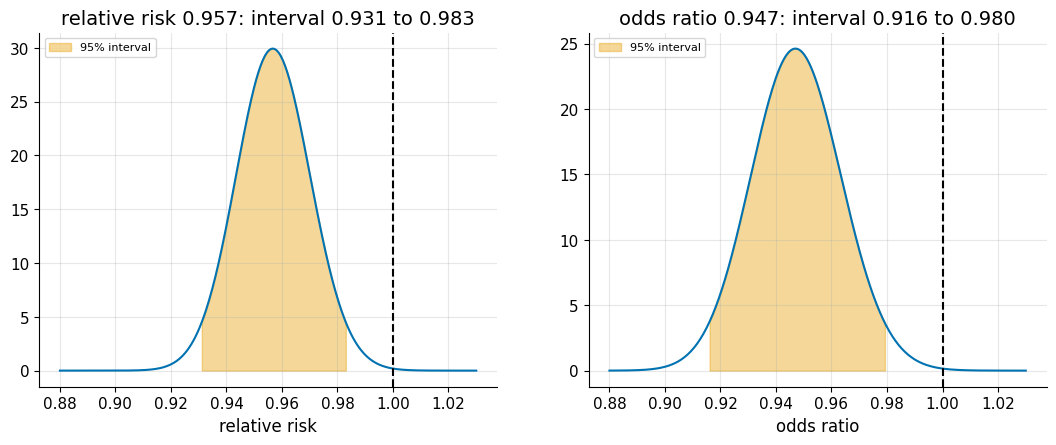

In [11]:
xs = np.linspace(0.88, 1.03, 400); fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, est, ci_, nm in [(axes[0], rr, ci_rr, "relative risk"), (axes[1], orr, ci_or, "odds ratio")]:
    sd = (np.log(ci_[1]) - np.log(ci_[0])) / 3.92; ax.plot(xs, stats.norm.pdf(np.log(xs), np.log(est), sd) / xs, color=MAIN); ax.fill_between(xs, stats.norm.pdf(np.log(xs), np.log(est), sd) / xs, where=(xs >= ci_[0]) & (xs <= ci_[1]), color=SIM, alpha=0.4, label="95% interval"); ax.axvline(1, color="black", linestyle="--"); ax.set_xlabel(nm); ax.set_title(f"{nm} {est:.3f}: interval {ci_[0]:.3f} to {ci_[1]:.3f}"); ax.legend(fontsize=8)
plt.show()

### 11.5 Interpretation and decision (Example 1)
- Players who saw the later gate returned **0.82 points less** often: RR **0.957** (95 % interval 0.931 to 0.983), OR **0.947** (0.916 to 0.980). The two ratios are close because retention at 7 days is fairly rare (about 19 %), and both intervals exclude 1. Fisher's exact p-value (0.00159) matches the chi-square p-value (0.00155).
- A relative drop of 4.3 % sounds small, but the **number needed to harm is 122**: for every 122 players shown the later gate, one fewer comes back after a week. Simulation confirms the interval (coverage 94.9 %).
- **Decision.** Report the risk difference and the RR together (a 4 % relative drop from 19 %), not only one of them; this supports the "do not ship" decision of 06_07.

---
### Example 2: a small case-control study (Fisher's exact test)
**Scenario.** Among 20 patients with a disease, 12 were exposed to a chemical; among 30 healthy controls only 5 were.

**Questions.** (1) Odds ratio with a 95 % interval. (2) Exact test p-value. (3) Why can the RR not be estimated from this design?

### 11.6 By hand
$\mathrm{OR}=\dfrac{12\times25}{8\times5}=7.5$; $\mathrm{SE}(\log\mathrm{OR})=\sqrt{\frac1{12}+\frac18+\frac15+\frac1{25}}=0.669$, interval $e^{\log7.5\pm1.312}=(2.0,\,27.8)$. The exact p-value is the Hypergeometric tail below.

OR = 7.5, Woolf CI = [ 2.02 27.86], exact conditional CI = [ 1.72 34.87], Fisher p = 0.00236, chi-square p = 0.00153
simulated P(>= 12 exposed among the 20 cases): 0.00194 | exact: 0.00206


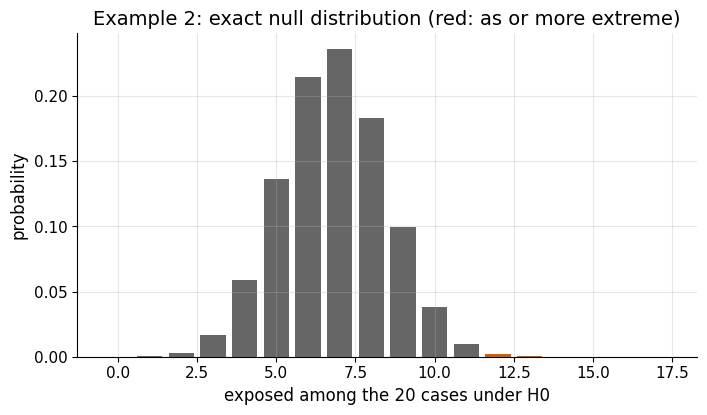

In [12]:
t2 = [[12, 8], [5, 25]]; or2 = 12 * 25 / (8 * 5); se2 = np.sqrt(1 / 12 + 1 / 8 + 1 / 5 + 1 / 25); ci2 = np.exp(np.log(or2) + np.array([-1.96, 1.96]) * se2); fe2 = stats.fisher_exact(t2)
tail = sum(stats.hypergeom.pmf(k, 50, 17, 20) for k in range(12, 18)) * 2
print(f"OR = {or2}, Woolf CI = {np.round(ci2, 2)}, exact conditional CI = {np.round([stats.contingency.odds_ratio(t2).confidence_interval().low, stats.contingency.odds_ratio(t2).confidence_interval().high], 2)}, Fisher p = {fe2.pvalue:.5f}, chi-square p = {stats.chi2_contingency(t2, correction=False)[1]:.5f}")
assert or2 == 7.5 and abs(fe2.pvalue - 0.00236) < 1e-4 and abs(ci2[0] - 2.02) < 0.05 and fe2.pvalue < 0.005
sim = np.random.default_rng(2); draws = sim.hypergeometric(17, 33, 20, 100000); print("simulated P(>= 12 exposed among the 20 cases):", np.mean(draws >= 12), "| exact:", round(sum(stats.hypergeom.pmf(k, 50, 17, 20) for k in range(12, 18)), 5))
xk = np.arange(0, 18); fig, ax = plt.subplots(figsize=(8, 4.2)); ax.bar(xk, stats.hypergeom.pmf(xk, 50, 17, 20), color=[HIGHLIGHT if k >= 12 else NEUTRAL for k in xk]); ax.set_xlabel("exposed among the 20 cases under H0"); ax.set_ylabel("probability"); ax.set_title("Example 2: exact null distribution (red: as or more extreme)")
plt.show()

### 11.7 Interpretation and decision (Example 2)
- Exposure is much more common among cases: **OR = 7.5**, Woolf interval 2.0 to 27.9 (the exact conditional interval is 1.7 to 34.9), Fisher p = **0.0024**. With only 50 people the interval is very wide: the exposure is clearly associated with the disease, but the strength is poorly known.
- The exact Hypergeometric tail (0.0021 for 12 or more exposed cases, one-sided) matches a simulation of 100,000 draws (0.0019); the Pearson chi-square p-value (0.0015) is slightly too small for such small counts.
- A case-control study fixes the numbers of cases and controls, so it cannot estimate the **risk** of disease in the exposed; only the odds ratio is valid.
- **Decision.** Treat as a signal to study further with a cohort or a larger study; report the OR with its wide interval and the exact p-value.

---
### Example 3: when does the odds ratio mislead? (simulation)
**Scenario.** A treatment multiplies a risk by 1.5. Compare the OR in a rare-outcome setting ($p_0=0.02$) and a common-outcome setting ($p_0=0.40$).

**Questions.** (1) True RR and OR in both settings. (2) How often does a study report "the odds ratio is at least 2" although the RR is 1.5?

p0 = 0.02: p1 = 0.03, RR = 1.5, OR = 1.515
p0 = 0.4: p1 = 0.60, RR = 1.5, OR = 2.250
common outcome: share of studies with OR >= 2: 0.9659 | median OR 2.2502813132954915


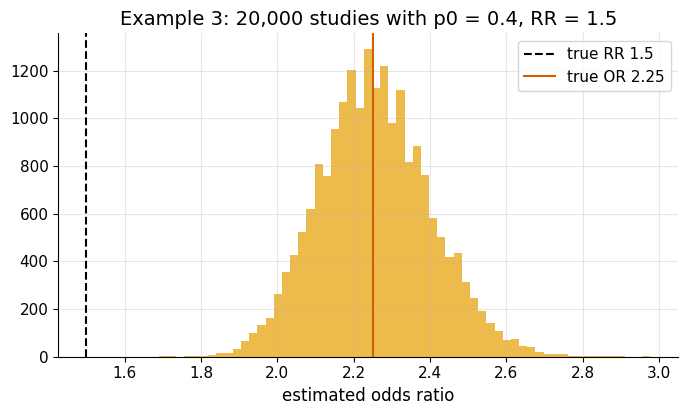

In [13]:
for p0_ in (0.02, 0.40):
    p1_ = 1.5 * p0_; print(f"p0 = {p0_}: p1 = {p1_:.2f}, RR = 1.5, OR = {(p1_ / (1 - p1_)) / (p0_ / (1 - p0_)):.3f}")
g = np.random.default_rng(8); n_ = 2000; a_ = g.binomial(n_, 0.6, 20000); c_ = g.binomial(n_, 0.4, 20000); or_s = (a_ / (n_ - a_)) / (c_ / (n_ - c_)); print("common outcome: share of studies with OR >= 2:", np.mean(or_s >= 2), "| median OR", np.median(or_s))
assert abs((0.6 / 0.4) / (0.4 / 0.6) - 2.25) < 1e-9 and 0.9 < np.mean(or_s >= 2) < 0.99
fig, ax = plt.subplots(figsize=(8, 4.2)); ax.hist(or_s, bins=60, color=SIM, alpha=0.7); ax.axvline(1.5, color="black", linestyle="--", label="true RR 1.5"); ax.axvline(2.25, color=HIGHLIGHT, label="true OR 2.25"); ax.set_xlabel("estimated odds ratio"); ax.set_title("Example 3: 20,000 studies with p0 = 0.4, RR = 1.5"); ax.legend()
plt.show()

### 11.9 Interpretation and decision (Example 3)
- For a rare outcome ($p_0=0.02$) OR = 1.515 is almost the RR (1.5). For a common outcome ($p_0=0.40$) the same RR of 1.5 corresponds to **OR = 2.25**.
- In 20,000 simulated studies with $p_0=0.4$ the estimated OR is at least 2 in **96.6 %** of them although the risk is only 1.5 times higher: a headline "the odds double" would badly overstate a 50 % increase in risk.
- **Decision.** For common outcomes report RR and the absolute risk difference; use the OR when the design requires it (case-control, logistic regression) and say what it means.

## 12. Where it is used
- **Statistics and medicine:** clinical trials (RR, NNT), epidemiology (case-control studies report ORs), meta-analysis.
- **Data science:** A/B test reporting, segment comparisons, risk scores.
- **ML and AI:** logistic-regression coefficients are log odds ratios; fairness metrics (disparate impact is a risk ratio); error-rate comparisons between groups.

## 13. Common pitfalls and misconceptions
- **Reading an OR as an RR** for common outcomes (Example 3).
- **Relative numbers without the baseline:** "doubles the risk" from 1 in 100,000 to 2 in 100,000 is a tiny absolute change; give the risk difference too.
- **Zero cells:** the log-based intervals fail; add 0.5 to each cell or use exact methods.
- **Case-control designs** cannot give risks; only the OR.
- **Chi-square on small counts:** use Fisher's exact test when an expected count is below 5.

## 14. Exercises
1. In a trial 30 of 200 treated and 50 of 200 control patients relapse. Compute RR, OR, the risk difference and the NNT.
2. Fisher's exact test for the table [[3, 7], [9, 1]].
3. For $p_0=0.3$ and $\mathrm{OR}=2$ find $p_1$ and the RR.
4. Simulate the coverage of the Woolf interval for $p_1=0.1$, $p_0=0.05$, $n=200$ per group.
5. (Harder) Using the Cookie Cats day-1 retention (20,034 of 44,700 and 20,119 of 45,489) give RR and OR with 95 % intervals.

Solutions are at the end.

## 15. Summary table

| Measure | Formula | Use |
|---|---|---|
| Risk difference | $p_1-p_0$ | absolute impact, NNT |
| Relative risk | $p_1/p_0$ | cohort studies, trials, A/B tests |
| Odds ratio | $ad/bc$ | case-control, logistic regression |
| Fisher exact | Hypergeometric tail | small tables |
| scipy | `fisher_exact`, `contingency.relative_risk`, `contingency.odds_ratio` | |

## Solutions

In [14]:
p1_, p0_ = 30 / 200, 50 / 200; print(f"1: RR {p1_ / p0_:.3f}, OR {(p1_ / (1 - p1_)) / (p0_ / (1 - p0_)):.3f}, risk difference {p1_ - p0_:.3f}, NNT {1 / abs(p1_ - p0_):.0f}")
print("2: Fisher exact p =", round(stats.fisher_exact([[3, 7], [9, 1]]).pvalue, 4), "(odds ratio", round(stats.fisher_exact([[3, 7], [9, 1]]).statistic, 3), ")")
o_ = 2 * 0.3 / 0.7; p1x = o_ / (1 + o_); print(f"3: p1 = {p1x:.4f}, RR = {p1x / 0.3:.4f}")
g = np.random.default_rng(1); a_ = g.binomial(200, 0.1, 20000) + 0.5; c_ = g.binomial(200, 0.05, 20000) + 0.5
b_ = 200 - (a_ - 0.5) + 0.5; d_ = 200 - (c_ - 0.5) + 0.5; est = np.log(a_ * d_ / (b_ * c_)); se_ = np.sqrt(1 / a_ + 1 / b_ + 1 / c_ + 1 / d_); true = np.log((0.1 / 0.9) / (0.05 / 0.95)); print("4: coverage", round(np.mean((est - 1.96 * se_ <= true) & (true <= est + 1.96 * se_)), 4))
q1, q0, m1, m0 = 20119, 20034, 45489, 44700; rr5 = (q1 / m1) / (q0 / m0); se5 = np.sqrt(1 / q1 - 1 / m1 + 1 / q0 - 1 / m0); or5 = (q1 / (m1 - q1)) / (q0 / (m0 - q0)); so5 = np.sqrt(1 / q1 + 1 / (m1 - q1) + 1 / q0 + 1 / (m0 - q0))
print("5: RR", round(rr5, 4), np.round(np.exp(np.log(rr5) + np.array([-1.96, 1.96]) * se5), 4), "| OR", round(or5, 4), np.round(np.exp(np.log(or5) + np.array([-1.96, 1.96]) * so5), 4))

1: RR 0.600, OR 0.529, risk difference -0.100, NNT 10
2: Fisher exact p = 0.0198 (odds ratio 0.048 )
3: p1 = 0.4615, RR = 1.5385
4: coverage 0.9606
5: RR 0.9868 [0.9725 1.0013] | OR 0.9764 [0.9511 1.0024]


**1.** $p_1=0.15$, $p_0=0.25$: RR **0.600**, OR **0.529**, risk difference $-0.10$, NNT **10** (treat 10 patients to prevent one relapse).

**2.** Fisher exact p = **0.0198** (sample odds ratio $3\times1/(7\times9)=0.048$): the first group has far lower odds.

**3.** Odds $2\times0.3/0.7=0.857$, so $p_1=0.4615$ and RR $=1.538$ (the OR of 2 corresponds to only 54 % more risk).

**4.** Coverage of the Woolf interval (with 0.5 added to each cell) is about **96 %**, slightly above 95 % (conservative at this size).

**5.** Day 1: RR **0.987** (0.973 to 1.001), OR **0.976** (0.951 to 1.002): intervals contain 1, consistent with p = 0.074 in 06_07; the direction is the same as for day 7.